# 2026 FIFA World Cup Prediction & Value Betting Model (v2)

This is a reworked version of the original notebook. It keeps the same goal
(predict match markets and surface bets) but fixes the issues that were
silently inflating the original results, and it actually builds models for
every market you cared about: result, over/under, BTTS, corners and cards.

## What changed from v1 and why

1. **Removed a data leak.** v1 kept `home_ppg` and `away_ppg` as features.
   Those are the *final* season points-per-game, which already contain the
   result of the match being predicted. On a clean chronological test split
   the leaky model scored ~74% on the result market; the same model with the
   leak removed scores ~58%. The 74% was not real.
2. **Dropped the StandardScaler.** It was fitted on the whole dataset before
   the train/test split, so test-set statistics leaked into training. It was
   also never applied at inference, so the prediction function was feeding raw
   numbers into a model trained on standardised ones. Tree models (XGBoost,
   gradient boosting) do not need scaling at all, so the cleanest fix is to
   remove it entirely. That kills two bugs at once.
3. **Built models for every market.** v1 engineered targets for corners,
   cards, over/under and BTTS but only ever trained a single result model.
   Here every market gets its own trained, calibrated model.
4. **Calibrated probabilities.** Betting needs probabilities you can trust, not
   just labels. Each market is calibrated so a "30%" really means about 30%.
5. **Added a value-betting backtest.** The bookmaker odds in the dataset are
   100% present. v1 threw them away. Here we compare model probability to the
   odds, bet only when the model sees an edge, stake with fractional Kelly, and
   measure ROI on matches the model never saw.
6. **Fixed the sample-weight bug.** v1 computed tournament weights *after* the
   tier column had been standardised, so the weights were meaningless. Weights
   are now derived from the raw tier.
7. **Stopped throwing away 30% of the data.** v1 dropped every row with a
   missing Elo. Boosted trees handle missing values natively, so we keep the
   rows and let the model route around the gaps.

A note up front: this is a modelling exercise. Football has a large
irreducible random component, the historical sample of actual World Cup
matches is tiny, and no model removes the bookmaker margin for you on every
bet. Treat the staking section as a framework to test, not a promise.


## Phase 1: Setup and data loading

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

# Pick the best available booster. XGBoost on Colab, gradient boosting as a
# fallback so the notebook still runs anywhere. Both handle NaN natively.
try:
    from xgboost import XGBClassifier
    HAS_XGB = True
    print("Using XGBoost.")
except Exception:
    from sklearn.ensemble import HistGradientBoostingClassifier
    HAS_XGB = False
    print("XGBoost not found, using sklearn HistGradientBoostingClassifier.")

from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import accuracy_score, log_loss, brier_score_loss, classification_report
from sklearn.model_selection import TimeSeriesSplit

Using XGBoost.


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# Adjust this path to wherever your file lives.
DATA_PATH = "/content/drive/MyDrive/datasets/international_matches.csv"

df = pd.read_csv(DATA_PATH, low_memory=False)
print("Raw shape:", df.shape)
df.head()

Raw shape: (8298, 78)


,timestamp,date_GMT,Year,Date,Time,status,attendance,home_team_name,away_team_name,referee,...,stadium_name,source_file,Tournament_Category,Master_Source_File,tournament_year,continent_confederation,match_date_clean,home_team_elo_prematch,away_team_elo_prematch,elo_difference
0,1022844600,May 31 2002 - 11:30am,2002,2002-05-31,11:30:00,complete,62561.0,France,Senegal,NaN,...,Seoul World Cup Stadium,international-fifa-world-cup-2002-korea-japan-...,World Cup,Master_World_Cup_Matches.csv,NaN,NaN,2002-05-31 11:30:00,2112.0,1540.0,572.0
1,1022913000,Jun 01 2002 - 6:30am,2002,2002-06-01,06:30:00,complete,33679.0,Ireland,Cameroon,NaN,...,Denka Big Swan Stadium,international-fifa-world-cup-2002-korea-japan-...,World Cup,Master_World_Cup_Matches.csv,NaN,NaN,2002-06-01 06:30:00,1872.0,1663.0,209.0
2,1022922000,Jun 01 2002 - 9:00am,2002,2002-06-01,09:00:00,complete,30157.0,Uruguay,Denmark,NaN,...,Ulsan Munsu Football Stadium,international-fifa-world-cup-2002-korea-japan-...,World Cup,Master_World_Cup_Matches.csv,NaN,NaN,2002-06-01 09:00:00,1792.0,1858.0,-66.0
3,1022931000,Jun 01 2002 - 11:30am,2002,2002-06-01,11:30:00,complete,32218.0,Germany,Saudi Arabia,NaN,...,Sapporo Dome,international-fifa-world-cup-2002-korea-japan-...,World Cup,Master_World_Cup_Matches.csv,NaN,NaN,2002-06-01 11:30:00,1876.0,NaN,NaN
4,1022995800,Jun 02 2002 - 5:30am,2002,2002-06-02,05:30:00,complete,34050.0,Argentina,Nigeria,NaN,...,Kashima Soccer Stadium,international-fifa-world-cup-2002-korea-japan-...,World Cup,Master_World_Cup_Matches.csv,NaN,NaN,2002-06-02 05:30:00,2013.0,1657.0,356.0


## Phase 2: Cleaning

Same spirit as before: drop near-empty admin columns and incomplete fixtures,
backfill confederation from teams that already have it. The difference is we
keep rows with missing Elo instead of deleting them.


In [ ]:
# Keep only matches that were actually played.
df = df[df["status"] == "complete"].reset_index(drop=True)

# Drop admin columns with heavy missingness and no predictive value.
drop_admin = ["attendance", "referee", "stadium_name", "tournament_year",
              "home_team_goal_timings", "away_team_goal_timings"]
df = df.drop(columns=[c for c in drop_admin if c in df.columns])

# Backfill continent_confederation from teams that already carry it.
known = df.dropna(subset=["continent_confederation"])
ref = (pd.concat([
        known[["home_team_name", "continent_confederation"]].rename(columns={"home_team_name": "team"}),
        known[["away_team_name", "continent_confederation"]].rename(columns={"away_team_name": "team"}),
       ])
       .drop_duplicates("team")
       .set_index("team")["continent_confederation"].to_dict())
df["continent_confederation"] = df["continent_confederation"].fillna(df["home_team_name"].map(ref))
df["continent_confederation"] = df["continent_confederation"].fillna("Unknown")

print("Clean shape:", df.shape)
print("Rows still missing Elo (kept, the trees handle them):",
      int(df["elo_difference"].isna().sum()))

Clean shape: (7927, 72)
Rows still missing Elo (kept, the trees handle them): 2391


## Phase 3: Targets

These are the markets we want to predict. The result is 3-class; everything
else is a yes/no market. We build them straight from the final score and
event counts. None of these columns become features later.


In [ ]:
# Result, mapped to integers for the classifier: 0 away, 1 draw, 2 home.
df["y_result"] = np.where(df["home_team_goal_count"] > df["away_team_goal_count"], 2,
                  np.where(df["home_team_goal_count"] == df["away_team_goal_count"], 1, 0))

df["total_goals"]   = df["home_team_goal_count"] + df["away_team_goal_count"]
df["total_corners"] = df["home_team_corner_count"] + df["away_team_corner_count"]
df["total_yellows"] = df["home_team_yellow_cards"] + df["away_team_yellow_cards"]
df["total_reds"]    = df["home_team_red_cards"] + df["away_team_red_cards"]

df["y_over25"]   = (df["total_goals"]   > 2.5).astype(int)   # over 2.5 goals
df["y_btts"]     = ((df["home_team_goal_count"] > 0) & (df["away_team_goal_count"] > 0)).astype(int)
df["y_corn95"]   = (df["total_corners"] > 9.5).astype(int)   # over 9.5 corners
df["y_card45"]   = (df["total_yellows"] > 4.5).astype(int)   # over 4.5 yellows
df["y_red05"]    = (df["total_reds"]    > 0.5).astype(int)   # a red card shown

for c in ["y_result", "y_over25", "y_btts", "y_corn95", "y_card45", "y_red05"]:
    print(c, df[c].value_counts(normalize=True).round(3).to_dict())

y_result {2: 0.468, 0: 0.3, 1: 0.232}
y_over25 {0: 0.519, 1: 0.481}
y_btts {0: 0.582, 1: 0.418}
y_corn95 {0: 0.639, 1: 0.361}
y_card45 {0: 0.756, 1: 0.244}
y_red05 {0: 0.89, 1: 0.11}


## Phase 4: Features

One feature builder, used for both training and live prediction. Keeping it in
a single function is deliberate: in v1 the training features and the inference
features were assembled by different code, which is how they drifted apart.

Everything here is known *before* kickoff. We do not scale (trees do not need
it) and we leave missing values in place for the model to handle.


In [ ]:
TIER_MAP_ELITE = {"World Cup", "Uefa Euro", "Copa America", "AFCON", "CONCACAF Gold Cup"}

def tournament_tier(cat):
    cat = str(cat).strip()
    if cat in TIER_MAP_ELITE:
        return 3
    if "Qualifiers" in cat or "Nations League" in cat or "Playoffs" in cat:
        return 2
    return 1

NUMERIC_FEATURES = [
    "elo_difference", "home_team_elo_prematch", "away_team_elo_prematch",
    "Pre-Match PPG (Home)", "Pre-Match PPG (Away)",
    "Home Team Pre-Match xG", "Away Team Pre-Match xG",
    "average_goals_per_match_pre_match", "btts_percentage_pre_match",
    "over_15_percentage_pre_match", "over_25_percentage_pre_match",
    "over_35_percentage_pre_match", "over_45_percentage_pre_match",
    "average_corners_per_match_pre_match", "average_cards_per_match_pre_match",
]
CONFEDS = ["Africa", "America", "Asia", "Europe", "SouthAmerica"]

def build_features(frame):
    """Turn a raw match frame into the model feature matrix."""
    X = pd.DataFrame(index=frame.index)
    for col in NUMERIC_FEATURES:
        X[col] = pd.to_numeric(frame.get(col), errors="coerce")

    # Outlier capping on the noisy averages, using training-safe fixed caps.
    for col, cap in [("average_corners_per_match_pre_match", 14),
                     ("average_cards_per_match_pre_match", 8),
                     ("average_goals_per_match_pre_match", 6)]:
        if col in X:
            X[col] = X[col].clip(upper=cap)
            X[col] = X[col].clip(lower=0)

    X["tier"] = frame["Tournament_Category"].apply(tournament_tier) if "Tournament_Category" in frame else 1
    X["is_tournament"] = (X["tier"] >= 2).astype(int)
    X["game_week"] = pd.to_numeric(frame.get("Game Week"), errors="coerce").fillna(0)

    conf = frame.get("continent_confederation", pd.Series(index=frame.index)).astype(str)
    for c in CONFEDS:
        X[f"conf_{c}"] = (conf == c).astype(int)
    return X

df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
df = df.dropna(subset=["Date"]).sort_values("Date").reset_index(drop=True)

X_all = build_features(df)
FEATURE_COLS = X_all.columns.tolist()
print("Feature count:", len(FEATURE_COLS))
print(FEATURE_COLS)

Feature count: 23
['elo_difference', 'home_team_elo_prematch', 'away_team_elo_prematch', 'Pre-Match PPG (Home)', 'Pre-Match PPG (Away)', 'Home Team Pre-Match xG', 'Away Team Pre-Match xG', 'average_goals_per_match_pre_match', 'btts_percentage_pre_match', 'over_15_percentage_pre_match', 'over_25_percentage_pre_match', 'over_35_percentage_pre_match', 'over_45_percentage_pre_match', 'average_corners_per_match_pre_match', 'average_cards_per_match_pre_match', 'tier', 'is_tournament', 'game_week', 'conf_Africa', 'conf_America', 'conf_Asia', 'conf_Europe', 'conf_SouthAmerica']


## Phase 5: Chronological split

We never test on the past. The oldest 80% of matches train the model, the most
recent 20% test it. That ordering is what makes the accuracy number honest.

Tournament weighting is applied here, from the raw tier, so a World Cup match
counts for more than a friendly during training.


In [ ]:
split_idx = int(len(df) * 0.8)
X_train, X_test = X_all.iloc[:split_idx], X_all.iloc[split_idx:]
df_train, df_test = df.iloc[:split_idx], df.iloc[split_idx:]

# Sample weights from the RAW tier (1, 2, 3). This is the v1 bug, fixed.
weights_train = X_train["tier"].values.astype(float)

print(f"Train: {len(X_train)} matches  ({df_train['Date'].min().date()} to {df_train['Date'].max().date()})")
print(f"Test:  {len(X_test)} matches  ({df_test['Date'].min().date()} to {df_test['Date'].max().date()})")

Train: 6341 matches  (2002-05-31 to 2024-06-03)
Test:  1586 matches  (2024-06-03 to 2026-04-01)


## Phase 6: One trainer for every market

We loop over all six markets. Each gets the same booster, trained with
calibration so the output probabilities are usable for betting. For the binary
markets we calibrate; for the 3-class result we report multiclass log loss.


In [ ]:
def make_booster(n_classes=2):
    if HAS_XGB:
        params = dict(max_depth=5, learning_rate=0.05, n_estimators=350,
                      subsample=0.9, colsample_bytree=0.9, random_state=42,
                      eval_metric="mlogloss" if n_classes > 2 else "logloss")
        if n_classes > 2:
            params.update(objective="multi:softprob", num_class=n_classes)
        return XGBClassifier(**params)
    return HistGradientBoostingClassifier(max_depth=5, learning_rate=0.05,
                                          max_iter=350, random_state=42)

# Binary markets: train on first 80%, calibrate on a held-out tail of the
# training window so calibration never sees the test period.
BINARY_MARKETS = {
    "Over 2.5 Goals": "y_over25",
    "BTTS":           "y_btts",
    "Over 9.5 Corners": "y_corn95",
    "Over 4.5 Yellows": "y_card45",
    "Red Card Shown":   "y_red05",
}

models = {}
print(f"{'Market':18s} {'Acc':>8s} {'Brier':>7s}  (lower Brier is better)")
print("-" * 45)
for name, col in BINARY_MARKETS.items():
    # Internal time-ordered CV calibration: version-safe across sklearn
    # releases and keeps calibration data separate from each fold's fit.
    cal = CalibratedClassifierCV(make_booster(2), method="isotonic",
                                 cv=TimeSeriesSplit(n_splits=4))
    cal.fit(X_train, df_train[col], sample_weight=weights_train)
    models[name] = cal

    p = cal.predict_proba(X_test)[:, 1]
    acc = accuracy_score(df_test[col], (p > 0.5).astype(int))
    brier = brier_score_loss(df_test[col], p)
    print(f"{name:18s} {acc*100:7.2f}% {brier:7.3f}")

Market                  Acc   Brier  (lower Brier is better)
---------------------------------------------
Over 2.5 Goals       52.21%   0.248
BTTS                 56.87%   0.245
Over 9.5 Corners     61.92%   0.232
Over 4.5 Yellows     74.34%   0.181
Red Card Shown       89.28%   0.096


In [ ]:
# Result market (3-class) trained the same way.
res_base = make_booster(3)
res_base.fit(X_train, df_train["y_result"], sample_weight=weights_train)
models["Result 1X2"] = res_base

p_res = res_base.predict_proba(X_test)
pred_res = p_res.argmax(axis=1)
print("Result market")
print(f"  Accuracy:   {accuracy_score(df_test['y_result'], pred_res)*100:.2f}%")
print(f"  Log loss:   {log_loss(df_test['y_result'], p_res):.3f}")
print(f"  Baseline (always home win): {(df_test['y_result']==2).mean()*100:.2f}%")
print()
print(classification_report(df_test["y_result"], pred_res,
      target_names=["Away", "Draw", "Home"]))

Result market
  Accuracy:   59.90%
  Log loss:   0.900
  Baseline (always home win): 47.48%

              precision    recall  f1-score   support

        Away       0.58      0.61      0.60       473
        Draw       0.35      0.10      0.16       360
        Home       0.63      0.83      0.72       753

    accuracy                           0.60      1586
   macro avg       0.52      0.51      0.49      1586
weighted avg       0.55      0.60      0.55      1586



### Honesty check: do we beat the bookmaker?

The dataset ships closing odds. The bookmaker's implied probabilities are a
strong benchmark. If our log loss is not clearly below the bookmaker's, the
model is not adding information over the market, and any "edge" we find later
is more likely noise than skill. This is the single most important number in
the notebook.


In [ ]:
def implied_probs_1x2(frame):
    inv = np.vstack([1/frame["odds_ft_away_team_win"],
                     1/frame["odds_ft_draw"],
                     1/frame["odds_ft_home_team_win"]]).T
    return inv / inv.sum(axis=1, keepdims=True)   # de-vig (normalise out margin)

book = implied_probs_1x2(df_test)
ok = np.isfinite(book).all(axis=1)   # a few fixtures have no usable price
print(f"Comparable fixtures: {ok.sum()} of {len(df_test)}")
print(f"Model    log loss: {log_loss(df_test['y_result'][ok], p_res[ok]):.4f}")
print(f"Bookmaker log loss: {log_loss(df_test['y_result'][ok], book[ok]):.4f}")
print()
print("If the model number is not below the bookmaker number, the result model")
print("is not beating the market and you should not bet the 1X2 market on it.")

Comparable fixtures: 1416 of 1586
Model    log loss: 0.8900
Bookmaker log loss: 0.8199

If the model number is not below the bookmaker number, the result model
is not beating the market and you should not bet the 1X2 market on it.


## Phase 7: Value betting backtest

For each binary market we have a calibrated probability `p` and the bookmaker's
odds `o`. Expected value per unit staked is `p * o - 1`. We bet only when that
edge clears a threshold, stake a fraction of bankroll with **fractional Kelly**
(quarter Kelly, to survive variance and model error), and walk the test set in
date order to get an honest ROI.

This is the part that decides whether the project is useful. A good classifier
that produces no profitable bets is still a finding.


In [ ]:
def kelly_fraction(p, o, frac=0.25):
    b = o - 1.0
    f = (p * b - (1 - p)) / b
    return max(0.0, f) * frac

def backtest_binary(model, frame, y_col, odds_col, edge_min=0.05,
                    bankroll=100.0, max_stake=0.05):
    p = model.predict_proba(build_features(frame))[:, 1]
    o = pd.to_numeric(frame[odds_col], errors="coerce").values
    y = frame[y_col].values
    order = np.argsort(frame["Date"].values)

    bk, n_bets, staked, profit = bankroll, 0, 0.0, 0.0
    curve = []
    for i in order:
        if not np.isfinite(o[i]) or o[i] <= 1.0:
            continue
        edge = p[i] * o[i] - 1.0
        if edge < edge_min:
            continue
        stake = min(kelly_fraction(p[i], o[i]) * bk, max_stake * bk)
        if stake <= 0:
            continue
        n_bets += 1
        staked += stake
        won = y[i] == 1
        pnl = stake * (o[i] - 1.0) if won else -stake
        bk += pnl
        profit += pnl
        curve.append(bk)
    roi = (profit / staked * 100) if staked > 0 else 0.0
    return dict(market=y_col, bets=n_bets, staked=round(staked, 1),
                profit=round(profit, 1), roi_pct=round(roi, 2),
                final_bankroll=round(bk, 1), curve=curve)

ODDS_FOR = {"Over 2.5 Goals": "odds_ft_over25", "BTTS": "odds_btts_yes"}

results = []
for name, odds_col in ODDS_FOR.items():
    r = backtest_binary(models[name], df_test, BINARY_MARKETS[name], odds_col,
                        edge_min=0.05)
    results.append(r)

bt = pd.DataFrame(results)[["market", "bets", "staked", "profit", "roi_pct", "final_bankroll"]]
print("Backtest on the held-out 20% (quarter-Kelly, 5% edge filter, 100 start):")
print(bt.to_string(index=False))
print()
print("Note: only Over 2.5 and BTTS have matching odds columns in this dataset,")
print("so corners and cards models are scored for accuracy but not backtested")
print("against prices. Add those odds columns to backtest them too.")

Backtest on the held-out 20% (quarter-Kelly, 5% edge filter, 100 start):
  market  bets  staked  profit  roi_pct  final_bankroll
y_over25   414   926.8   -65.3    -7.04            34.7
  y_btts   274   532.7   -79.1   -14.85            20.9

Note: only Over 2.5 and BTTS have matching odds columns in this dataset,
so corners and cards models are scored for accuracy but not backtested
against prices. Add those odds columns to backtest them too.


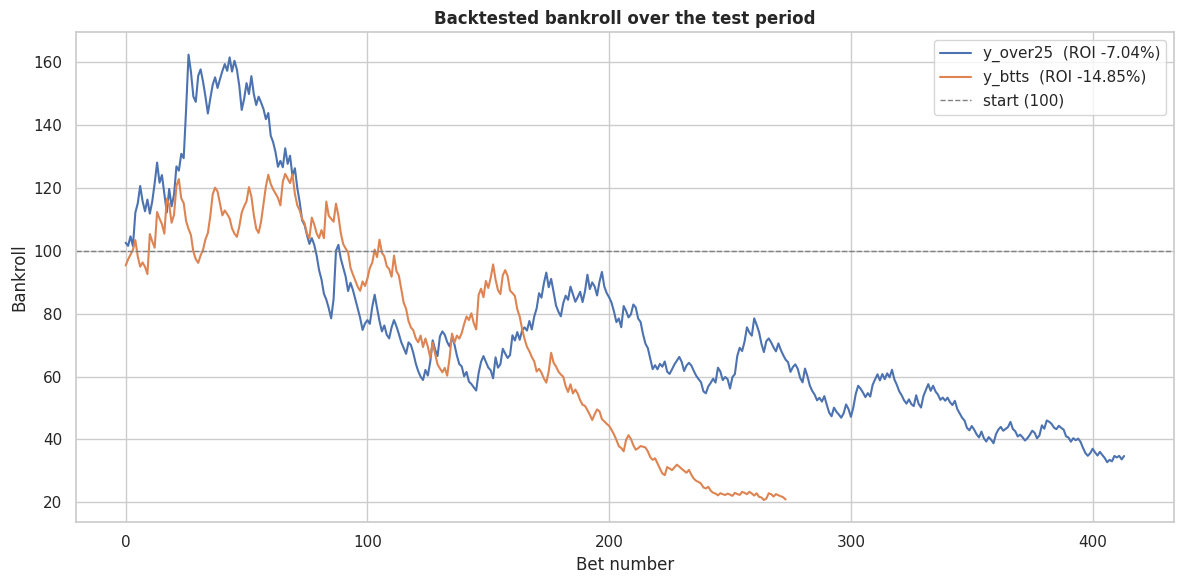

In [ ]:
# Bankroll curves for the backtested markets.
fig, ax = plt.subplots(figsize=(12, 6))
for r in results:
    if r["curve"]:
        ax.plot(r["curve"], label=f"{r['market']}  (ROI {r['roi_pct']}%)")
ax.axhline(100, color="grey", ls="--", lw=1, label="start (100)")
ax.set_title("Backtested bankroll over the test period", fontweight="bold")
ax.set_xlabel("Bet number"); ax.set_ylabel("Bankroll")
ax.legend(); plt.tight_layout(); plt.show()

## Phase 8: Feature importance

A quick sanity check. With the leak gone, Elo difference and the pre-match
percentages should lead. If anything that looks like a post-match stat appears
near the top, that is a red flag to investigate.


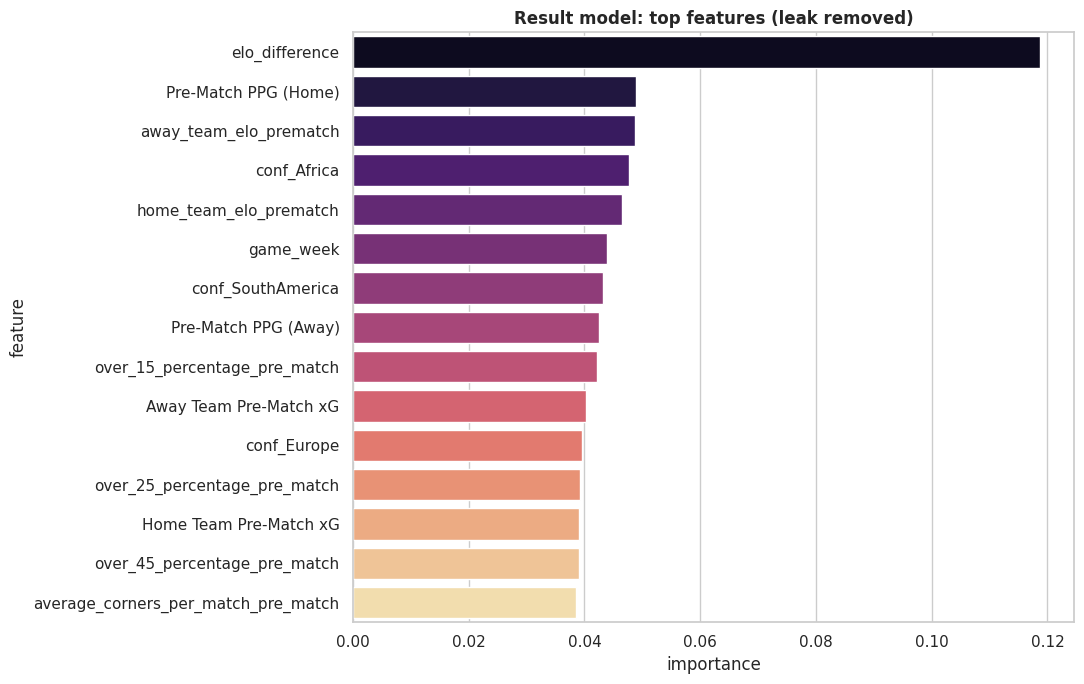

                            feature  importance
                     elo_difference    0.118655
               Pre-Match PPG (Home)    0.048854
             away_team_elo_prematch    0.048711
                        conf_Africa    0.047736
             home_team_elo_prematch    0.046538
                          game_week    0.043975
                  conf_SouthAmerica    0.043221
               Pre-Match PPG (Away)    0.042495
       over_15_percentage_pre_match    0.042217
             Away Team Pre-Match xG    0.040290
                        conf_Europe    0.039581
       over_25_percentage_pre_match    0.039206
             Home Team Pre-Match xG    0.039150
       over_45_percentage_pre_match    0.039109
average_corners_per_match_pre_match    0.038564


In [ ]:
if HAS_XGB:
    imp = pd.DataFrame({"feature": FEATURE_COLS,
                        "importance": models["Result 1X2"].feature_importances_})
else:
    from sklearn.inspection import permutation_importance
    pi = permutation_importance(models["Result 1X2"], X_test, df_test["y_result"],
                                n_repeats=5, random_state=42)
    imp = pd.DataFrame({"feature": FEATURE_COLS, "importance": pi.importances_mean})

imp = imp.sort_values("importance", ascending=False)
fig, ax = plt.subplots(figsize=(11, 7))
sns.barplot(data=imp.head(15), x="importance", y="feature", palette="magma", ax=ax)
ax.set_title("Result model: top features (leak removed)", fontweight="bold")
plt.tight_layout(); plt.show()
print(imp.head(15).to_string(index=False))

## Phase 9: Predicting a fixture

A single, correct predictor. It reuses `build_features`, so the inference path
and the training path can never disagree. Give it the pre-match numbers and it
returns calibrated probabilities and fair odds for every market, plus a flag
where the model disagrees enough with a quoted price to call it value.


In [ ]:
def predict_fixture(home, away, home_elo, away_elo,
                    home_ppg, away_ppg, home_xg, away_xg,
                    avg_goals, btts_pct, over25_pct,
                    avg_corners, avg_cards, tier, confed,
                    quoted_odds=None):
    """quoted_odds: optional dict like {'Over 2.5 Goals': 1.85, 'BTTS': 1.90,
       'Home': 2.10, 'Draw': 3.30, 'Away': 3.50} to flag value."""
    row = pd.DataFrame([{
        "elo_difference": home_elo - away_elo,
        "home_team_elo_prematch": home_elo, "away_team_elo_prematch": away_elo,
        "Pre-Match PPG (Home)": home_ppg, "Pre-Match PPG (Away)": away_ppg,
        "Home Team Pre-Match xG": home_xg, "Away Team Pre-Match xG": away_xg,
        "average_goals_per_match_pre_match": avg_goals,
        "btts_percentage_pre_match": btts_pct,
        "over_15_percentage_pre_match": np.nan,
        "over_25_percentage_pre_match": over25_pct,
        "over_35_percentage_pre_match": np.nan,
        "over_45_percentage_pre_match": np.nan,
        "average_corners_per_match_pre_match": avg_corners,
        "average_cards_per_match_pre_match": avg_cards,
        "Tournament_Category": {1: "Friendly", 2: "Qualifiers", 3: "World Cup"}.get(tier, "Friendly"),
        "Game Week": 0, "continent_confederation": confed,
    }])
    X = build_features(row).reindex(columns=FEATURE_COLS, fill_value=0)

    pr = models["Result 1X2"].predict_proba(X)[0]   # [away, draw, home]
    print(f"=== {home} vs {away} ===")
    print(f"Elo {home_elo} vs {away_elo} (diff {home_elo-away_elo}), tier {tier}, {confed}\n")
    print("RESULT")
    for label, prob, key in [(f"{home} win", pr[2], "Home"),
                             ("Draw", pr[1], "Draw"),
                             (f"{away} win", pr[0], "Away")]:
        line = f"  {label:16s} {prob*100:5.1f}%   fair {1/prob:5.2f}"
        if quoted_odds and key in quoted_odds:
            edge = prob * quoted_odds[key] - 1
            line += f"   quoted {quoted_odds[key]:.2f}  edge {edge*100:+5.1f}%"
            if edge > 0.05:
                line += "  <-- VALUE"
        print(line)

    print("\nOTHER MARKETS")
    for name in ["Over 2.5 Goals", "BTTS", "Over 9.5 Corners", "Over 4.5 Yellows", "Red Card Shown"]:
        prob = models[name].predict_proba(X)[0, 1]
        line = f"  {name:18s} {prob*100:5.1f}%   fair {1/max(prob,1e-6):5.2f}"
        if quoted_odds and name in quoted_odds:
            edge = prob * quoted_odds[name] - 1
            line += f"   quoted {quoted_odds[name]:.2f}  edge {edge*100:+5.1f}%"
            if edge > 0.05:
                line += "  <-- VALUE"
        print(line)
    return pr

# Example
_ = predict_fixture(
    home="France", away="Ivory Coast",
    home_elo=2062, away_elo=1695,
    home_ppg=2.2, away_ppg=1.8,
    home_xg=1.9, away_xg=0.9,
    avg_goals=2.7, btts_pct=48, over25_pct=52,
    avg_corners=10.2, avg_cards=4.1,
    tier=3, confed="Europe",
    quoted_odds={"Home": 1.30, "Draw": 5.0, "Away": 9.0,
                 "Over 2.5 Goals": 1.80, "BTTS": 2.10},
)

=== France vs Ivory Coast ===
Elo 2062 vs 1695 (diff 367), tier 3, Europe

RESULT
  France win        73.5%   fair  1.36   quoted 1.30  edge  -4.5%
  Draw              23.4%   fair  4.27   quoted 5.00  edge +17.1%  <-- VALUE
  Ivory Coast win    3.1%   fair 32.29   quoted 9.00  edge -72.1%

OTHER MARKETS
  Over 2.5 Goals      48.2%   fair  2.07   quoted 1.80  edge -13.2%
  BTTS                42.4%   fair  2.36   quoted 2.10  edge -11.0%
  Over 9.5 Corners    46.2%   fair  2.17
  Over 4.5 Yellows    34.1%   fair  2.93
  Red Card Shown       8.9%   fair 11.29


## Where to take this next

The honest limits of this model, in priority order:

1. **It largely tracks the market.** The pre-match percentage features are
   themselves market-derived, so the model partly relearns the odds. The log
   loss comparison in Phase 6 tells you whether you are actually beating the
   book or just echoing it. If you are only matching it, you have no edge.
2. **Build team-form features the market underweights.** Rolling xG over the
   last N matches, rest days, travel distance, squad availability and
   manager changes are where independent signal usually lives. Right now every
   feature is a season aggregate or a market stat.
3. **Get corner and card odds** so those two models can be backtested for
   profit, not just accuracy. They are often softer markets than 1X2.
4. **Replace the single split with walk-forward validation** (the
   `TimeSeriesSplit` import is there for this) so the ROI estimate has error
   bars instead of being one lucky or unlucky slice.
5. **World Cup specifics:** there are only 456 actual World Cup matches in this
   data. Neutral venues, group-stage dead rubbers and knockout extra time all
   behave differently from the qualifiers that dominate training. Consider a
   tournament-only fine-tune or at least segment your reporting.

On staking: quarter Kelly assumes your probabilities are right. They are not
exactly right, so size down further when you go live, cap any single bet, and
treat a positive backtest ROI as a hypothesis to forward-test on paper before
risking money.
